# 08 - A BESS fleet with extra physics: subclassing `VectorizedContainerAdapter`

energysim ships a fast, deliberately simple `BatteryFleetAdapter`: an energy bucket with one
round-trip efficiency, a SoC window and power limits. It is the right tool for thousands of
home batteries in a load-flow study. It is the wrong tool when the question is about
*the battery itself*: how hot does a 4-hour container get in a desert summer, what does
the thermal-management system cost, how much capacity is gone after five years, and what
is the round-trip efficiency once the auxiliary load is metered?

This notebook builds a vectorized fleet class, `BESSPhysicsFleet`, that adds that physics
while keeping the same N-unit NumPy structure. It is a template: the framework does the
plumbing (signals, connections, outputs, aggregation), and the class holds the physics.

Notes on the numbers:
- energysim ships **no manufacturer data**. Every per-unit value comes from a small
  `BESSDatasheet` dataclass that you fill in from your own datasheet or test report. The
  values in this notebook are illustrative and are not taken from any product.
- The electrical model is the same Rint equivalent circuit as the built-in `BatteryBESS`
  (open-circuit voltage in series with an internal resistance), so the cross-check in
  section 3 is a like-for-like test.

## 1. Why the built-in fleet is not enough

| Physics | `BatteryFleetAdapter` | `BESSPhysicsFleet` (this notebook) |
|---|---|---|
| Efficiency | one constant `efficiency` | inverter efficiency curve vs. load ratio, Rint joule losses vs. SoC |
| Voltage / resistance | none | OCV(SoC) and Rin(SoC) as curves, scaled per unit |
| Temperature | none | 1-state thermal model per unit, `C_th` and `R_th` per unit |
| Temperature limits | none | power derate from a `Curve1D` of cell temperature |
| Ageing | none | Arrhenius calendar fade plus throughput-based cycle fade |
| Auxiliary load | none | thermal-management power (cooling above 25 C, heating below 10 C) |

The question these physics answer: a 2-hour and a 4-hour container at 0.5 MW do the same
arbitrage, but the 4-hour unit sees a lower C-rate, and a hot site loses capacity faster.
Both effects change the revenue and the warranty case, and neither is visible in a flat
efficiency model.

## 2. The datasheet and the class

**Equations** (per unit *i*, power `P` positive = charge, AC side):

- Pack DC power: `P_dc = P / eta_inv(|P|/P_max)` on charge, `P / eta_inv` on discharge
  (`P < 0`), where `eta_inv` is a shared `Curve1D` of the load ratio.
- Rint operating point: `Voc(SoC) = V_nom * ocv_gain * shape_ocv(SoC)`,
  `Rin(SoC) = R_pack * rin_gain * shape_rin(SoC)`, and the current solves
  `Rin*I^2 + Voc*I - P_dc = 0`.
- SoC: `dSoC = Voc*I * dt / (C_eff * 3600)`, with `C_eff = C_nom * SOH`.
- Thermal: `C_th * dT/dt = I^2*Rin - (T - T_amb,site) / R_th`, where `T_amb,site` is the regional
  ambient plus the site offset.
- Power derate: the power limit is multiplied by `derate(T_batt)`, a `Curve1D`.
- Ageing: `dSOH = cal_fade * exp(-Ea/R (1/T - 1/T_ref)) * dt / year + eol_fade * FEC / cycle_life`,
  with `FEC = |P_dc| * dt / (2 * C_nom)`.
- Auxiliary load: `P_aux = P_standby + k_cool * max(0, T - 25) + k_heat * max(0, 10 - T)`,
  metered on the grid side.

Each unit scales the shared curve *shapes* with its own gains. Curve1D multipliers are
shared so that the fleet is one array operation per term, not one curve per unit.

In [1]:
import math
from dataclasses import dataclass
from typing import List, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from energysim import world
from energysim.container import VectorizedContainerAdapter, BatteryFleetAdapter
from energysim.models import BatteryBESS
from energysim.models.common import Curve1D

SEED = 2024
R_GAS = 8.314                      # J/(mol K)
SECONDS_PER_YEAR = 365.25 * 86400.0
YEAR_S = 365 * 86400

@dataclass(frozen=True)
class BESSDatasheet:
    """Per-unit values transcribed from a datasheet or test report.

    The defaults are illustrative. Replace them with your own measured or
    OEM-supplied numbers before using the results for anything real.
    """
    name: str
    capacity_mwh: float
    p_max_mw: float
    nominal_voltage_v: float = 800.0
    r_pack_ohm: Optional[float] = None    # None -> 3 % voltage drop at full power (BatteryBESS default)
    ocv_gain: float = 1.0                 # per-unit multiplier on the OCV shape
    rin_gain: float = 1.0                 # per-unit multiplier on the Rin shape
    c_th_kj_k: float = 50_000.0           # lumped pack heat capacity
    r_th_k_w: float = 0.002               # pack-to-ambient thermal resistance
    calendar_fade_pct_yr_25c: float = 2.0
    cycle_life_to_eol: float = 4000.0     # full equivalent cycles to reach eol_fade
    eol_fade: float = 0.20                # capacity fade at end of life (0.20 -> 80 % SOH)
    aux_standby_kw: float = 1.5           # BMS and controls, always on
    aux_cool_kw_per_k: float = 0.6        # cooling power per K above 25 C
    aux_heat_kw_per_k: float = 0.4        # heating power per K below 10 C
    t_site_offset_c: float = 0.0          # site microclimate offset from the regional ambient
    soc_init: float = 0.5
    t_init_c: float = 25.0


class BESSPhysicsFleet(VectorizedContainerAdapter):
    """N Li-ion containers: Rint circuit, 1-state thermal, ageing and thermal-management load."""

    # Declared units: inputs and outputs (state names are the output names).
    units = {
        "dispatch_frac": "1", "t_amb_degc": "degC",
        "p_actual_mw": "MW", "p_aux_mw": "MW", "soc": "1",
        "t_batt_degc": "degC", "soh": "1", "q_heat_kw": "kW",
    }

    # Shared curve shapes (same numbers as the built-in BatteryBESS defaults).
    OCV_SOC = [0.0, 0.05, 0.10, 0.20, 0.40, 0.60, 0.80, 0.90, 0.95, 1.0]
    OCV_MULT = [0.85, 0.92, 0.95, 0.98, 0.99, 1.00, 1.02, 1.05, 1.07, 1.10]
    RIN_SOC = [0.0, 0.1, 0.2, 0.5, 0.8, 0.9, 1.0]
    RIN_MULT = [3.0, 1.8, 1.2, 1.0, 1.0, 1.2, 1.5]
    INV_LOAD = [0.0, 0.05, 0.1, 0.2, 0.5, 0.75, 1.0]
    INV_EFF = [0.80, 0.88, 0.93, 0.96, 0.975, 0.97, 0.96]
    # Power derate vs. cell temperature (new in this class): full power from 10 to 40 C.
    DERATE_T = [-10.0, 0.0, 10.0, 40.0, 45.0, 55.0]
    DERATE_F = [0.40, 0.80, 1.00, 1.00, 0.70, 0.30]
    T_COOL_SP_C = 25.0
    T_HEAT_SP_C = 10.0

    def __init__(self, name: str, specs: List[BESSDatasheet], step_size: float = 3600.0,
                 soc_min: float = 0.05, soc_max: float = 0.95):
        if not specs:
            raise ValueError("BESSPhysicsFleet needs at least one BESSDatasheet.")
        super().__init__(name=name, size=len(specs), step_size=step_size)
        self.soc_min, self.soc_max = float(soc_min), float(soc_max)
        self.specs = list(specs)

        def vec(attr):
            return self._as_vector(np.array([getattr(s, attr) for s in specs], dtype=float), attr)

        r_pack = [s.r_pack_ohm if s.r_pack_ohm is not None
                  else 0.03 * s.nominal_voltage_v ** 2 / (s.p_max_mw * 1e6) for s in specs]
        self.cap_mwh = vec("capacity_mwh")
        self.p_max = vec("p_max_mw")
        self.v_nom = vec("nominal_voltage_v")
        self.r_pack = self._as_vector(np.array(r_pack, dtype=float), "r_pack_ohm")
        self.ocv_gain = vec("ocv_gain")
        self.rin_gain = vec("rin_gain")
        self.c_th = vec("c_th_kj_k")
        self.r_th = vec("r_th_k_w")
        self.cal_fade = vec("calendar_fade_pct_yr_25c")
        self.cycle_life = vec("cycle_life_to_eol")
        self.eol_fade = vec("eol_fade")
        self.aux_standby = vec("aux_standby_kw")
        self.aux_cool = vec("aux_cool_kw_per_k")
        self.aux_heat = vec("aux_heat_kw_per_k")
        self.t_offset = vec("t_site_offset_c")

        # Shared Curve1D shapes, evaluated once per step for the whole fleet.
        self.ocv_shape = Curve1D(self.OCV_SOC, self.OCV_MULT)
        self.rin_shape = Curve1D(self.RIN_SOC, self.RIN_MULT, min_val=0.0)
        self.inv_curve = Curve1D(self.INV_LOAD, self.INV_EFF, min_val=0.5, max_val=0.99)
        self.derate_curve = Curve1D(self.DERATE_T, self.DERATE_F, min_val=0.0, max_val=1.0)

        # States (outputs) and inputs.
        self.register_state("soc", vec("soc_init"))
        self.register_state("soh", 1.0)
        self.register_state("t_batt_degc", vec("t_init_c"))
        self.register_state("p_actual_mw", 0.0)
        self.register_state("p_aux_mw", 0.0)
        self.register_state("q_heat_kw", 0.0)
        self.register_input("dispatch_frac", 0.0)   # -1..1 of each unit's rating, + charge
        self.register_input("t_amb_degc", 25.0)     # regional ambient, broadcast to all sites
        self.register_alias("t_amb", "t_amb_degc")
        self.register_alias("p_frac", "dispatch_frac")

    @staticmethod
    def _solve_dc(p_req, voc, rin, p_max, curve):
        """Vectorized Rint solve (MW in, A out), the same form as BatteryBESS._solve_dc."""
        inv = np.asarray(curve(np.abs(p_req) / np.maximum(p_max, 1e-6)))
        p_dc_w = np.where(p_req > 0, p_req * inv * 1e6,
                          np.where(p_req < 0, p_req / inv * 1e6, 0.0))
        disc = voc ** 2 + 4.0 * rin * p_dc_w
        i_cell = np.where(disc >= 0.0,
                          (-voc + np.sqrt(np.maximum(disc, 0.0))) / (2.0 * rin),
                          -voc / (2.0 * rin))
        i_cell = np.where(p_req == 0.0, 0.0, i_cell)
        p_dc_w = (voc + i_cell * rin) * i_cell
        return p_dc_w / 1e6, i_cell, inv

    def step(self, time: float, step_size: Optional[float] = None) -> None:
        dt = float(step_size) if step_size is not None else self.step_size
        if dt <= 0.0:
            return
        soc = self.states["soc"]
        soh = self.states["soh"]
        t_batt = self.states["t_batt_degc"]
        frac = np.clip(self.input_values["dispatch_frac"], -1.0, 1.0)
        t_amb = self.input_values["t_amb_degc"] + self.t_offset

        # 1. Power request, derated by cell temperature and blocked at the SoC limits.
        p_lim = self.p_max * np.asarray(self.derate_curve(t_batt))
        p_req = np.clip(frac * self.p_max, -p_lim, p_lim)
        p_req = np.where((p_req > 0) & (soc >= self.soc_max), 0.0, p_req)
        p_req = np.where((p_req < 0) & (soc <= self.soc_min), 0.0, p_req)

        # 2. Rint operating point at the start-of-step state.
        voc = self.v_nom * self.ocv_gain * np.asarray(self.ocv_shape(soc))
        rin = np.maximum(1e-5, self.r_pack * self.rin_gain * np.asarray(self.rin_shape(soc)))
        soc_per_mw_s = 1.0 / (self.cap_mwh * soh * 3600.0)
        p_dc, i_cell, inv = self._solve_dc(p_req, voc, rin, self.p_max, self.inv_curve)
        d_soc = voc * i_cell / 1e6 * dt * soc_per_mw_s

        # 3. Units that would cross a SoC limit get their request scaled down so SoC lands on
        #    the limit. Regula falsi on the scale factor; the SoC response is almost linear.
        new_soc = soc + d_soc
        cross = (d_soc != 0.0) & ((new_soc > self.soc_max) | (new_soc < self.soc_min))
        if np.any(cross):
            bound = np.where(new_soc > self.soc_max, self.soc_max, self.soc_min)[cross]
            p_full = p_req[cross]
            v_c, r_c = voc[cross], rin[cross]
            spm_c, pm_c, s0 = soc_per_mw_s[cross], self.p_max[cross], soc[cross]

            def gap(s):
                _, i_s, _ = self._solve_dc(p_full * s, v_c, r_c, pm_c, self.inv_curve)
                return s0 + v_c * i_s / 1e6 * dt * spm_c - bound

            lo, hi = np.zeros_like(p_full), np.ones_like(p_full)
            g_lo, g_hi = gap(lo), gap(hi)
            s = hi.copy()
            for _ in range(12):
                den = np.where(np.abs(g_hi - g_lo) > 1e-15, g_hi - g_lo, 1e-15)
                s = hi - g_hi * (hi - lo) / den
                g_s = gap(s)
                if np.max(np.abs(g_s)) < 1e-10:
                    break
                same = np.sign(g_s) == np.sign(g_hi)
                hi = np.where(same, s, hi)
                g_hi = np.where(same, g_s, g_hi)
                lo = np.where(same, lo, s)
                g_lo = np.where(same, g_lo, g_s)
            p_req = p_req.copy()
            p_req[cross] = p_full * s
            p_dc, i_cell, inv = self._solve_dc(p_req, voc, rin, self.p_max, self.inv_curve)
            d_soc = voc * i_cell / 1e6 * dt * soc_per_mw_s

        # 4. Terminal power and SoC update (same convention as BatteryBESS).
        p_act = np.where(p_req > 0, p_req, np.where(p_req < 0, np.maximum(p_req, p_dc * inv), 0.0))
        soc_new = np.clip(soc + d_soc, np.minimum(self.soc_min, soc), np.maximum(self.soc_max, soc))

        # 5. Thermal 1-state model: C dT/dt = I^2 R - (T - T_amb,site) / R_th.
        q_joule_w = i_cell ** 2 * rin
        q_cool_w = (t_batt - t_amb) / np.maximum(self.r_th, 1e-6)
        t_new = t_batt + (q_joule_w - q_cool_w) / (self.c_th * 1000.0) * dt

        # 6. Ageing: Arrhenius calendar fade and throughput-based cycle fade.
        arr = np.exp(-25000.0 / R_GAS * (1.0 / (t_new + 273.15) - 1.0 / 298.15))
        d_cal = (self.cal_fade / 100.0) / SECONDS_PER_YEAR * arr * dt
        fec = np.abs(p_dc) * (dt / 3600.0) / (2.0 * self.cap_mwh)
        d_cyc = self.eol_fade * fec / np.maximum(self.cycle_life, 1e-9)
        soh_new = np.maximum(0.5, soh - (d_cal + d_cyc))

        # 7. Thermal-management load, metered on the grid side (not fed back into the cell here).
        p_aux_kw = (self.aux_standby
                    + self.aux_cool * np.maximum(0.0, t_new - self.T_COOL_SP_C)
                    + self.aux_heat * np.maximum(0.0, self.T_HEAT_SP_C - t_new))

        self.states["soc"][:] = soc_new
        self.states["soh"][:] = soh_new
        self.states["t_batt_degc"][:] = t_new
        self.states["p_actual_mw"][:] = p_act
        self.states["p_aux_mw"][:] = p_aux_kw / 1000.0
        self.states["q_heat_kw"][:] = q_joule_w / 1000.0

## 3. Cross-check: one unit against the built-in `BatteryBESS`

The built-in model is the reference. We give the fleet a single unit with *identical*
parameters and drive both with the same command (a +/-25 % sinusoid, 12-hour period, 21 days,
25 C ambient). Inside the mid-SoC window (20 to 80 %) no SoC limit is active, so the two should
agree to numerical precision. We report the largest SoC difference and the temperature
difference, and assert the SoC difference is below 1e-3.

In [2]:
ref = BESSDatasheet(name="reference", capacity_mwh=1.0, p_max_mw=0.5)

bess = BatteryBESS(
    name="ref", capacity_mwh=ref.capacity_mwh, p_max_mw=ref.p_max_mw,
    soc_init=ref.soc_init, soc_min=0.05, soc_max=0.95,
    nominal_voltage_v=ref.nominal_voltage_v, c_th_kj_k=ref.c_th_kj_k, r_th_k_w=ref.r_th_k_w,
    t_init_c=ref.t_init_c, calendar_fade_pct_per_year_25c=ref.calendar_fade_pct_yr_25c,
    cycle_life_to_eol=ref.cycle_life_to_eol, eol_fade=ref.eol_fade, step_size=3600.0,
)
one = BESSPhysicsFleet("one_unit", [ref], step_size=3600.0)

hours = np.arange(24 * 21)
soc_dev, t_dev = [], []
for h in hours:
    t = float(h) * 3600.0
    frac = 0.25 * math.sin(2.0 * math.pi * h / 12.0)
    bess._inputs_val["P_cmd"] = frac * ref.p_max_mw   # MW, + charge
    bess._inputs_val["T_amb"] = 25.0
    bess.step_model(3600.0, t)
    one.set_value(["dispatch_frac", "t_amb_degc"], [frac, 25.0])
    one.step(t, 3600.0)
    if 0.20 <= bess.soc <= 0.80:                       # mid-SoC window only
        soc_dev.append(abs(bess.soc - one.states["soc"][0]))
        t_dev.append(abs(bess.t_batt_c - one.states["t_batt_degc"][0]))

max_soc_dev = max(soc_dev)
print(f"hours compared (mid-SoC window): {len(soc_dev)}")
print(f"max |SoC_fleet - SoC_BatteryBESS| = {max_soc_dev:.2e}")
print(f"max |T_fleet - T_BatteryBESS|     = {max(t_dev):.2e} K")
assert max_soc_dev < 1e-3, "fleet physics diverges from BatteryBESS"

hours compared (mid-SoC window): 321
max |SoC_fleet - SoC_BatteryBESS| = 9.21e-15
max |T_fleet - T_BatteryBESS|     = 2.31e-11 K


## 4. A heterogeneous fleet of 120 sites

The fleet mixes:
- **Durations**: 2-hour (1 MWh) and 4-hour (2 MWh) containers, both at 0.5 MW. The 4-hour
  container sees half the C-rate. Its thermal mass is also larger (`C_th` scales with energy).
- **Climates**: 60 hot sites (about +8 K above the regional ambient) and 60 cold sites
  (about -6 K). The offsets are the per-unit `t_site_offset_c` in the spec.
- **Cell-to-cell spread**: small random OCV and resistance gains.

Dispatch is a shared command for the whole fleet: charge 11:00 to 15:00 (+1 of rating),
discharge 18:00 to 21:00 (-1), idle otherwise. The regional ambient is seasonal plus
diurnal. A 2-hour container empties during the 3-hour evening peak and stops at its SoC floor.

A second fleet, `BatteryFleetAdapter`, is driven by the same command (in kW) on the same
sites, so the physics and the built-in model can be compared on identical operations.

In [3]:
N_SITES = 120
rng = np.random.default_rng(SEED)
durations_h = rng.choice([2.0, 4.0], size=N_SITES)
hot = rng.permutation(np.repeat([True, False], N_SITES // 2))
offsets = np.where(hot, rng.normal(8.0, 1.5, N_SITES), rng.normal(-6.0, 1.5, N_SITES))

specs = []
for i in range(N_SITES):
    cap = 0.5 * durations_h[i]
    specs.append(BESSDatasheet(
        name=f"site{i:03d}",
        capacity_mwh=cap,
        p_max_mw=0.5,
        ocv_gain=float(np.clip(rng.normal(1.0, 0.01), 0.97, 1.03)),
        rin_gain=float(np.clip(rng.normal(1.0, 0.05), 0.85, 1.25)),
        c_th_kj_k=50_000.0 * cap,                 # heat capacity scales with pack energy
        t_site_offset_c=float(offsets[i]),
        aux_cool_kw_per_k=0.6 if hot[i] else 0.3,  # hot sites run the chiller harder
        aux_heat_kw_per_k=0.1 if hot[i] else 0.5,  # cold sites run the heater
    ))

fleet = BESSPhysicsFleet("bess", specs, step_size=3600.0)


def tou_frac(t: float) -> float:
    """Time-of-use dispatch command, fraction of rating (+ charge, - discharge)."""
    h = (t / 3600.0) % 24.0
    if 11.0 <= h < 15.0:
        return 1.0
    if 18.0 <= h < 21.0:
        return -1.0
    return 0.0


def ambient_degc(t: float) -> float:
    """Regional ambient: seasonal swing (about +/-10 K) plus a diurnal swing (about +/-5 K)."""
    day = t / 86400.0
    hour = (t / 3600.0) % 24.0
    seasonal = 10.0 * math.sin(2.0 * math.pi * (day - 100.0) / 365.25)
    diurnal = 5.0 * math.sin(2.0 * math.pi * (hour - 9.0) / 24.0)
    return 12.0 + seasonal + diurnal


# Built-in comparison fleet: same sites, same energy, flat 95 % efficiency each way, no thermal.
builtin = BatteryFleetAdapter(
    name="builtin", size=N_SITES,
    capacity_kwh=np.array([1000.0 * c for c in (0.5 * durations_h)]),
    max_charge_kw=500.0, max_discharge_kw=500.0,
    initial_soc=0.5, soc_min=0.05, soc_max=0.95, efficiency=0.95,
    step_size=3600.0,
)

sim = world(start_time=0, stop_time=YEAR_S, t_macro=3600)
sim.add_signal("tou", tou_frac, step_size=3600, units={"y": "1"})
sim.add_signal("tou_kw", lambda t: 500.0 * tou_frac(t), step_size=3600, units={"y": "kW"})
sim.add_signal("amb", ambient_degc, step_size=3600, units={"y": "degC"})
sim.add_fleet(
    sim_name="bess", container=fleet, step_size=3600,
    outputs=["total_p_actual_mw", "total_p_aux_mw", "total_q_heat_kw",
             "mean_soc", "mean_soh", "min_soh", "mean_t_batt_degc", "min_t_batt_degc", "max_t_batt_degc"],
)
sim.add_fleet(
    sim_name="builtin", container=builtin, step_size=3600,
    outputs=["total_actual_p_kw", "mean_soc"],
)
sim.add_connections({
    "tou.y": "bess.dispatch_frac",
    "amb.y": "bess.t_amb_degc",
    "tou_kw.y": "builtin.p_cmd_kw",
})

res = sim.simulate(pbar=False)
df = res["bess"]
df_b = res["builtin"]
print(f"simulated {N_SITES} sites for one year, {len(df)} hourly records")
display(df.head(3))

simulated 120 sites for one year, 8761 hourly records


,total_p_actual_mw,total_p_aux_mw,total_q_heat_kw,mean_soc,mean_soh,min_soh,mean_t_batt_degc,min_t_batt_degc,max_t_batt_degc
time,,,,,,,,,
0.0,0.0,0.00,0.0,0.5,1.000000,1.000000,25.000000,25.000000,25.000000
3600.0,0.0,0.18,0.0,0.5,0.999998,0.999998,24.256810,23.682906,24.715603
7200.0,0.0,0.18,0.0,0.5,0.999996,0.999996,23.514498,22.384584,24.422004


## 5. Results: aggregate power, ageing and temperature

The world records fleet-level aggregates (`total_`, `mean_`, `min_`, `max_`). For a
per-site temperature distribution we replay the same fleet class hour by hour with the same
signals. This is a check as well as a plot: the replayed fleet mean should match the world's
`mean_t_batt_degc`.

max |replay mean T - world mean T| = 0.00e+00 K
2 h, hot   mean SOH after 1 yr = 96.25 %   site-hours above 40 C = 0.23 %
2 h, cold  mean SOH after 1 yr = 97.09 %   site-hours above 40 C = 0.00 %
4 h, hot   mean SOH after 1 yr = 96.15 %   site-hours above 40 C = 4.10 %
4 h, cold  mean SOH after 1 yr = 97.17 %   site-hours above 40 C = 0.00 %


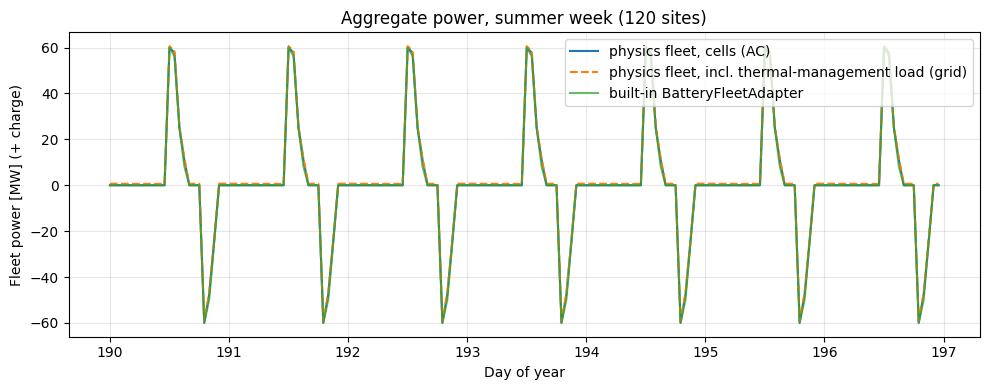

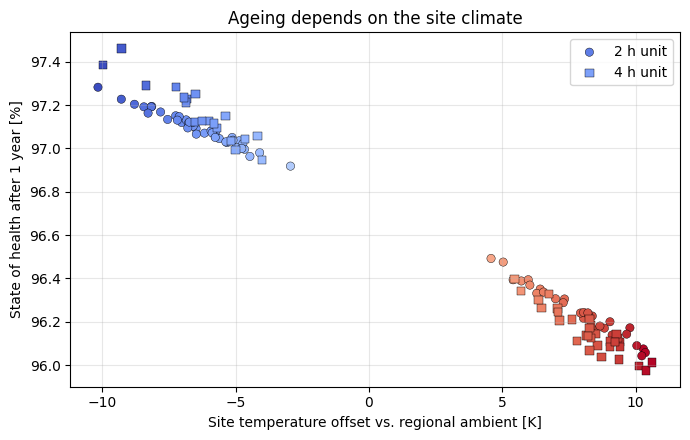

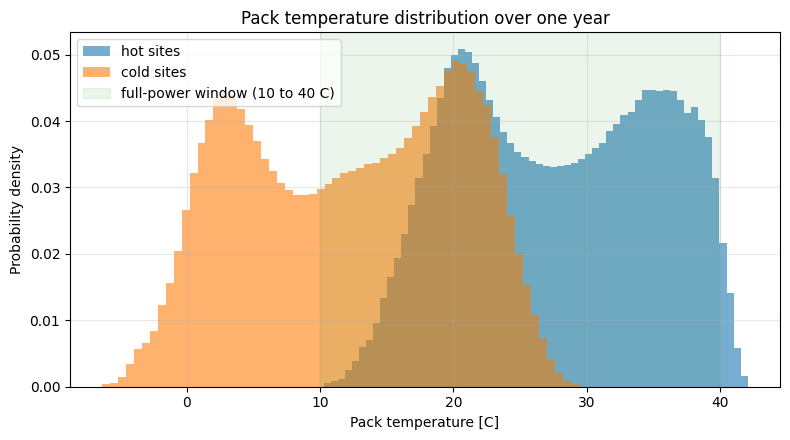

,charged [MWh],discharged [MWh],round-trip eff.
physics fleet (incl. aux),59059.5790,47608.338,0.8061
built-in BatteryFleetAdapter,54468.7812,49220.250,0.9036


physics, cells only (no aux): RTE = 0.862


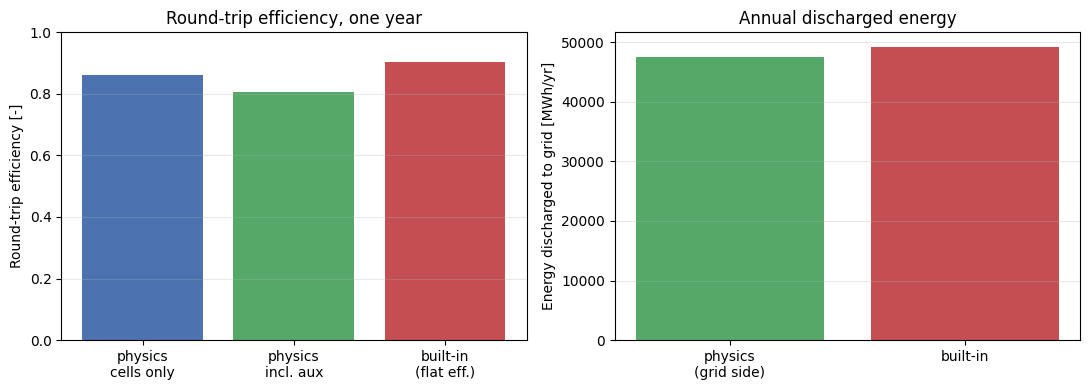

In [4]:
replay = BESSPhysicsFleet("replay", specs, step_size=3600.0)
hours_yr = np.arange(0, YEAR_S, 3600.0)
T_site = np.empty((len(hours_yr), N_SITES))
for k, t in enumerate(hours_yr):
    replay.set_value(["dispatch_frac", "t_amb_degc"], [tou_frac(t), ambient_degc(t)])
    replay.step(t, 3600.0)
    T_site[k] = replay.states["t_batt_degc"]
# The world row at time t holds the state after the step that started at t - 1 h, so row k + 1
# is compared with replay step k.
mean_gap = np.max(np.abs(T_site.mean(axis=1) - df["mean_t_batt_degc"].to_numpy()[1:len(hours_yr) + 1]))
print(f"max |replay mean T - world mean T| = {mean_gap:.2e} K")

soh_final = fleet.states["soh"].copy()
hot_mask = np.array(hot)

for label, m in (("2 h, hot", (durations_h == 2.0) & hot_mask), ("2 h, cold", (durations_h == 2.0) & ~hot_mask),
                 ("4 h, hot", (durations_h == 4.0) & hot_mask), ("4 h, cold", (durations_h == 4.0) & ~hot_mask)):
    print(f"{label:10s} mean SOH after 1 yr = {100 * soh_final[m].mean():.2f} %   "
          f"site-hours above 40 C = {100 * (T_site[:, m] > 40.0).mean():.2f} %")

# Figure 1: aggregate power over one summer week (fleet, with auxiliary load, and built-in).
w0, w1 = 190 * 24, 197 * 24
t_days = df.index.to_numpy()[w0:w1] / 86400.0
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(t_days, df["total_p_actual_mw"].to_numpy()[w0:w1], label="physics fleet, cells (AC)")
ax.plot(t_days, (df["total_p_actual_mw"] + df["total_p_aux_mw"]).to_numpy()[w0:w1],
        label="physics fleet, incl. thermal-management load (grid)", linestyle="--")
ax.plot(t_days, df_b["total_actual_p_kw"].to_numpy()[w0:w1] / 1000.0,
        label="built-in BatteryFleetAdapter", alpha=0.7)
ax.set_xlabel("Day of year")
ax.set_ylabel("Fleet power [MW] (+ charge)")
ax.set_title("Aggregate power, summer week (120 sites)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# Figure 2: SOH after one year vs. climate offset.
fig, ax = plt.subplots(figsize=(7, 4.5))
for dur, marker in ((2.0, "o"), (4.0, "s")):
    m = durations_h == dur
    sc = ax.scatter(np.asarray(offsets)[m], soh_final[m] * 100.0, marker=marker,
                    c=np.asarray(offsets)[m], cmap="coolwarm", s=36, edgecolor="k", linewidth=0.3,
                    label=f"{dur:.0f} h unit")
ax.set_xlabel("Site temperature offset vs. regional ambient [K]")
ax.set_ylabel("State of health after 1 year [%]")
ax.set_title("Ageing depends on the site climate")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# Figure 3: temperature distribution over all site-hours, hot vs. cold climates.
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(T_site[:, hot_mask].ravel(), bins=60, alpha=0.6, density=True, label="hot sites")
ax.hist(T_site[:, ~hot_mask].ravel(), bins=60, alpha=0.6, density=True, label="cold sites")
ax.axvspan(10.0, 40.0, color="green", alpha=0.08, label="full-power window (10 to 40 C)")
ax.set_xlabel("Pack temperature [C]")
ax.set_ylabel("Probability density")
ax.set_title("Pack temperature distribution over one year")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# Round-trip efficiency and energy comparison.
def discharged_mwh(p_mw):
    return float(-np.clip(p_mw, None, 0.0).sum() * 1.0)

def charged_mwh(p_mw):
    return float(np.clip(p_mw, 0.0, None).sum() * 1.0)

p_cells = df["total_p_actual_mw"].to_numpy()
p_grid = (df["total_p_actual_mw"] + df["total_p_aux_mw"]).to_numpy()
p_builtin = df_b["total_actual_p_kw"].to_numpy() / 1000.0

rte_cells = discharged_mwh(p_cells) / charged_mwh(p_cells)
rte_grid = discharged_mwh(p_grid) / charged_mwh(p_grid)
rte_builtin = discharged_mwh(p_builtin) / charged_mwh(p_builtin)

summary = pd.DataFrame({
    "charged [MWh]": [charged_mwh(p_grid), charged_mwh(p_builtin)],
    "discharged [MWh]": [discharged_mwh(p_grid), discharged_mwh(p_builtin)],
    "round-trip eff.": [rte_grid, rte_builtin],
}, index=["physics fleet (incl. aux)", "built-in BatteryFleetAdapter"])
display(summary.round(4))
print(f"physics, cells only (no aux): RTE = {rte_cells:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
labels = ["physics\ncells only", "physics\nincl. aux", "built-in\n(flat eff.)"]
axes[0].bar(labels, [rte_cells, rte_grid, rte_builtin], color=["#4c72b0", "#55a868", "#c44e52"])
axes[0].set_ylabel("Round-trip efficiency [-]")
axes[0].set_ylim(0.0, 1.0)
axes[0].set_title("Round-trip efficiency, one year")
axes[0].grid(axis="y", alpha=0.3)
axes[1].bar(["physics\n(grid side)", "built-in"], [discharged_mwh(p_grid), discharged_mwh(p_builtin)],
            color=["#55a868", "#c44e52"])
axes[1].set_ylabel("Energy discharged to grid [MWh/yr]")
axes[1].set_title("Annual discharged energy")
axes[1].grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 6. What the physics changes

Read the plots and the printed table together:

- **Aggregate power** follows the same command in both models. The physics curves differ
  from the built-in one by the losses, and the thermal-management load (dashed, grid side)
  is an extra draw that the built-in model does not have. It runs all day, so it matters most
  when the batteries are idle.
- **SOH** falls more on hot sites. The printed means show the gap. The main driver is the
  Arrhenius calendar term, which raises the calendar rate by roughly 40 % for every 10 K of
  extra pack temperature (Ea = 25 kJ/mol near 25 C). Duration matters less in this data: both sizes
  run the same 0.5 MW command, and the table shows the difference between sizes is small.
- **Temperature**: the hot sites spend a small share of hours above 40 C, where the power derate
  in `DERATE_F` engages. The 4-hour hot sites spend the most time there (a few per cent of
  hours), because they keep running at full power for longer, while the 2-hour units reach their
  SoC limits and stop. The built-in model has no such limit and keeps full power in those hours. The cold sites reach the heating setpoint in winter, which shows up as extra
  auxiliary load.

The round-trip efficiency bars separate the effects. The built-in model applies one number
(0.95 each way, about 0.90 round trip). The physics fleet gets its efficiency from the inverter
curve, the Rint joule losses and the auxiliary load, so it is lower and depends on the
operating point. The cells-only value isolates the electrical losses; including the auxiliary
load lowers the value further. The energy table shows the operational consequence: for the
same command, the physics fleet delivers less energy to the grid and draws more from it.

The numbers are illustrative. For a real study, replace every field of `BESSDatasheet` with
datasheet or test values, and calibrate `OCV_MULT`, `RIN_MULT`, `INV_EFF` and `DERATE_F`
to the cell and inverter test reports. The class structure does not change.

## Where to go next

- [06 - Large-scale vectorized fleet aggregation](06_vectorized_fleet_aggregation.ipynb):
  the built-in fleet adapters and how aggregation scales to 10,000 units.
- 10 - Heat pump building fleet (planned): the same subclassing pattern applied to thermal
  building stock, with comfort-band checks.
- 12 - DSO feeder with fleets (planned): hosting these fleets on a pandapower feeder to check
  voltage and loading.